# Figure 3 | Sequential Olympus
Frozen paper data: 19 tasks, six methods, 30 matched repeats. All metric definitions are imported from the core.


In [1]:
# ======================== SETTINGS ========================
ROOT_OVERRIDE = None
CAMPAIGNS = ("OLY-002",)
EXTRA_RESULT_ROOTS = ()  # Campaign roots, each containing results/trajectories/
INPUT_SNAPSHOT = True  # Record the frozen source in figure provenance.
Q = 1
MODELS = ("random", "optuna", "hebo", "vanilla_gp_qlogei", "yj_qlogei", "qmace_retained")
METRICS = ("final_regret", "nAUC")  # Rows, in this order
BASELINE = "vanilla_gp_qlogei"
CVAR_ALPHA = 0.90
N_BOOT, BOOT_SEED = 10000, 20261105
BAR_CI_LINEWIDTH = 1.1
MIN_PAIRED_REPEATS = 30
REQUIRE_ALL_19_TASKS = True
SAVE_HISTORY = False
SAVE_FIGURES = True
FIGSIZE = (8.4, 5.3)
# Appearance (font sizes and widths are in points).
FONT_SCALE = 1.25       # Increase/decrease all plot fonts together.
RANK_LINEWIDTH = 2.4    # Horizontal rank intervals.
RANK_MARKERSIZE = 7.0   # Rank dots.
BAR_ALPHA = 0.95       # 1 = fully saturated; previous PDF bars were about 0.78.
LABELS = {"random": "random", "optuna": "optuna", "hebo": "HEBO",
          "vanilla_gp_qlogei": "qLogEI",
          "yj_qlogei": "tidyHEBO\nw/qLogEI", "qmace_retained": "tidyHEBO"}
COLORS = {"random": "tab:blue", "optuna": "tab:green", "hebo": "tab:purple",
          "vanilla_gp_qlogei": "tab:orange", "yj_qlogei": "tab:brown",
          "qmace_retained": "tab:red"}
# ==========================================================

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, importlib.metadata, inspect, json, os, sys, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

def locate_root():
    if ROOT_OVERRIDE:
        return Path(ROOT_OVERRIDE).expanduser().resolve()
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "src/bo_benchmark").is_dir():
            return p
    raise FileNotFoundError("Set ROOT_OVERRIDE to the benchmark project directory")

ROOT = locate_root()
sys.path.insert(0, str(ROOT / "src"))
from bo_benchmark.analysis.metrics import regret_auc, summarize_auc
from bo_benchmark.analysis.comparison import scores, validate_record, protocol_key
from bo_benchmark.task_catalog import load_catalog
from bo_benchmark.campaign import expand_path

assert Q == 1, "Figure 4 is sequential; use q=1"
assert 0 < CVAR_ALPHA < 1 and MIN_PAIRED_REPEATS >= 1
assert set(METRICS) <= {"nAUC", "final_regret"} and len(set(METRICS)) == len(METRICS)
assert MODELS and len(MODELS) == len(set(MODELS))
assert set(MODELS) <= LABELS.keys() and set(MODELS) <= COLORS.keys()
TASKS = sorted(load_catalog())
def digest(b):
    return hashlib.sha256(b).hexdigest()
def json_bytes(obj):
    return json.dumps(obj, sort_keys=True, ensure_ascii=False, allow_nan=False,
                      separators=(",", ":")).encode("utf-8")
metric_sources = {p.name: p for p in {
    Path(inspect.getfile(regret_auc)), Path(inspect.getfile(scores)),
    Path(inspect.getfile(load_catalog))}}
metric_hashes = {n: digest(p.read_bytes()) for n,p in metric_sources.items()}

In [3]:
from bo_benchmark_app.paper import history_records
from bo_benchmark.seeds import SeedManager
all_records, history_manifest = history_records("olympus", ROOT)
history_key = next(key for key in history_manifest["sha256"] if Path(key).name.startswith("olympus."))
snapshot = ROOT / history_key
snapshot_id = history_manifest["sha256"][history_key][:16]
campaign_file = ROOT / "experiments/OLY-002.json"
campaign_configs = {"OLY-002": json.loads(campaign_file.read_text(encoding="utf-8-sig"))} if campaign_file.is_file() else {}


In [4]:
# Historical files are immutable; figures never rewrite the source data.


In [5]:
from bo_benchmark.analysis.metrics import olympus_run_table, olympus_statistics, sequential_olympus_summary
runs = olympus_run_table(all_records, TASKS, MODELS, (1,), SeedManager(42,30).seeds)
task_metrics, long_summary = olympus_statistics(runs, MODELS, (1,), baseline=BASELINE,
    alpha=CVAR_ALPHA, draws=N_BOOT, seed=BOOT_SEED)
summary = sequential_olympus_summary(task_metrics, long_summary)
coverage = runs.groupby(["task","optimizer"]).size().unstack("optimizer").reset_index()
used_tasks, excluded = TASKS, []
display(summary.round(4))


mean  ...  cvar_delta_high
metric       optimizer                   ...                 
final_regret hebo                0.1457  ...           0.0522
             optuna              0.1655  ...           0.0419
             qmace_retained      0.1024  ...          -0.0153
             random              0.2166  ...           0.0890
             vanilla_gp_qlogei   0.1313  ...           0.0000
             yj_qlogei           0.1214  ...           0.0028
nAUC         hebo               19.3199  ...           6.4691
             optuna             21.2203  ...           4.7826
             qmace_retained     15.6302  ...           0.3555
             random             24.9403  ...           9.0279
             vanilla_gp_qlogei  16.8937  ...           0.0000
             yj_qlogei          16.3394  ...           0.8926

[12 rows x 12 columns]

In [6]:
# Style: manuscript colors, stronger rank intervals, compact rows; no legend.
def plot_figure(summary):
    style = {"font.family":"DejaVu Sans", "font.size":7.3,
        "axes.titlesize":8.5, "axes.titleweight":"bold", "axes.labelsize":7,
        "xtick.labelsize":6.6, "ytick.labelsize":7.1,
        "axes.linewidth":.8, "pdf.fonttype":42, "ps.fonttype":42}
    for key in ("font.size", "axes.titlesize", "axes.labelsize",
                "xtick.labelsize", "ytick.labelsize"):
        style[key] *= FONT_SCALE
    with plt.rc_context(style):
        height = FIGSIZE[1] + max(0, len(MODELS)-6)*.32
        fig = plt.figure(figsize=(FIGSIZE[0], height), layout="constrained")
        fig.set_constrained_layout_pads(w_pad=.025, h_pad=.015, wspace=.025, hspace=.015)
        rows = np.atleast_1d(fig.subfigures(nrows=len(METRICS), ncols=1, hspace=.015))
        y = np.arange(len(MODELS))
        titles = ("Mean rank ↓", "Δ Mean vs qLogEI ↓", f"Δ CVaR{CVAR_ALPHA*100:g} vs qLogEI ↓")
        for i,metric in enumerate(METRICS):
            part = summary.loc[metric].reindex(MODELS)
            row_name = "nAUC" if metric == "nAUC" else "Final regret"
            rows[i].suptitle(f"{chr(65+i)}   {row_name}", x=.012, ha="left",
                             fontsize=10*FONT_SCALE, fontweight="bold")
            axes = np.atleast_1d(rows[i].subplots(1, 3))
            for j,col in enumerate(("rank","mean_delta","cvar_delta")):
                ax = axes[j]
                ax.set_axisbelow(True)
                ax.grid(axis="x", color=".88", linewidth=.60)
                ax.spines[["top","right"]].set_visible(False)
                ax.spines["left"].set_color(".65")
                ax.spines["bottom"].set_color(".45")
                ax.tick_params(axis="both", length=1.5, width=.4, colors=".3", pad=2)
                ax.tick_params(axis="y", length=0)
                ax.set_yticks(y, [LABELS[m] for m in MODELS])
                ax.tick_params(axis="y", labelleft=(j==0))
                ax.set_ylim(len(MODELS)-.1,-.6)
                ax.set_title(titles[j], pad=2)
                values = part[col].to_numpy()
                if j == 0:
                    for yi,m in enumerate(MODELS):
                        ax.axhline(yi, color=".90", lw=.60, zorder=0)
                        value = part.loc[m,"rank"]
                        ax.errorbar(value, yi, xerr=np.array([[value-part.loc[m,"rank_low"]],
                                  [part.loc[m,"rank_high"]-value]]), fmt="o",
                            color=COLORS[m], markersize=RANK_MARKERSIZE, markeredgecolor="white",
                            markeredgewidth=.8, capsize=4,
                            elinewidth=RANK_LINEWIDTH, capthick=.8*RANK_LINEWIDTH)
                        ax.annotate(f"{value:.2f}", (value,yi), xytext=(5,-11),
                                    textcoords="offset points", fontsize=6*FONT_SCALE, color=".2",
                                    bbox=dict(facecolor="white", edgecolor="none", pad=.12))
                    ax.set_xlim(1, len(MODELS)+.15)
                    ax.set_xticks(range(1,len(MODELS)+1))
                    ax.set_xlabel("Average rank (1 = best)",labelpad=2)
                else:
                    ax.axvline(0, color="#555555", lw=.85, ls=(0,(3,2)), zorder=3)
                    ax.barh(y, values, height=.42, color=[COLORS[m] for m in MODELS],
                            alpha=BAR_ALPHA, edgecolor=[COLORS[m] for m in MODELS], linewidth=.60)
                    lower = part[col+"_low"].to_numpy()
                    upper = part[col+"_high"].to_numpy()
                    # Draw percentile endpoints directly; no assumption that the estimate
                    # must lie within its percentile interval.
                    ax.hlines(y, lower, upper, color="#303030", linewidth=BAR_CI_LINEWIDTH, zorder=4)
                    ax.vlines(lower, y-.07, y+.07, color="#303030", linewidth=BAR_CI_LINEWIDTH, zorder=4)
                    ax.vlines(upper, y-.07, y+.07, color="#303030", linewidth=BAR_CI_LINEWIDTH, zorder=4)
                    lo = min(0,float(lower.min()),float(values.min()))
                    hi = max(0,float(upper.max()),float(values.max()))
                    span = max(hi-lo,1e-8)
                    ax.set_xlim(lo-.08*span if lo else 0, hi+.23*span)
                    for yi,value in enumerate(values):
                        ax.annotate((f"{value:+.2g}" if value else "0"), (value,yi), xytext=(5,-11),
                                    textcoords="offset points", fontsize=6*FONT_SCALE, color=".2",
                                    bbox=dict(facecolor="white", edgecolor="none", pad=.12))
                    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
                    ax.set_xlabel("Mean paired difference",labelpad=2)
        return fig

fig = plot_figure(summary)
plt.show()

Figure and analysis: ./figures/olympus


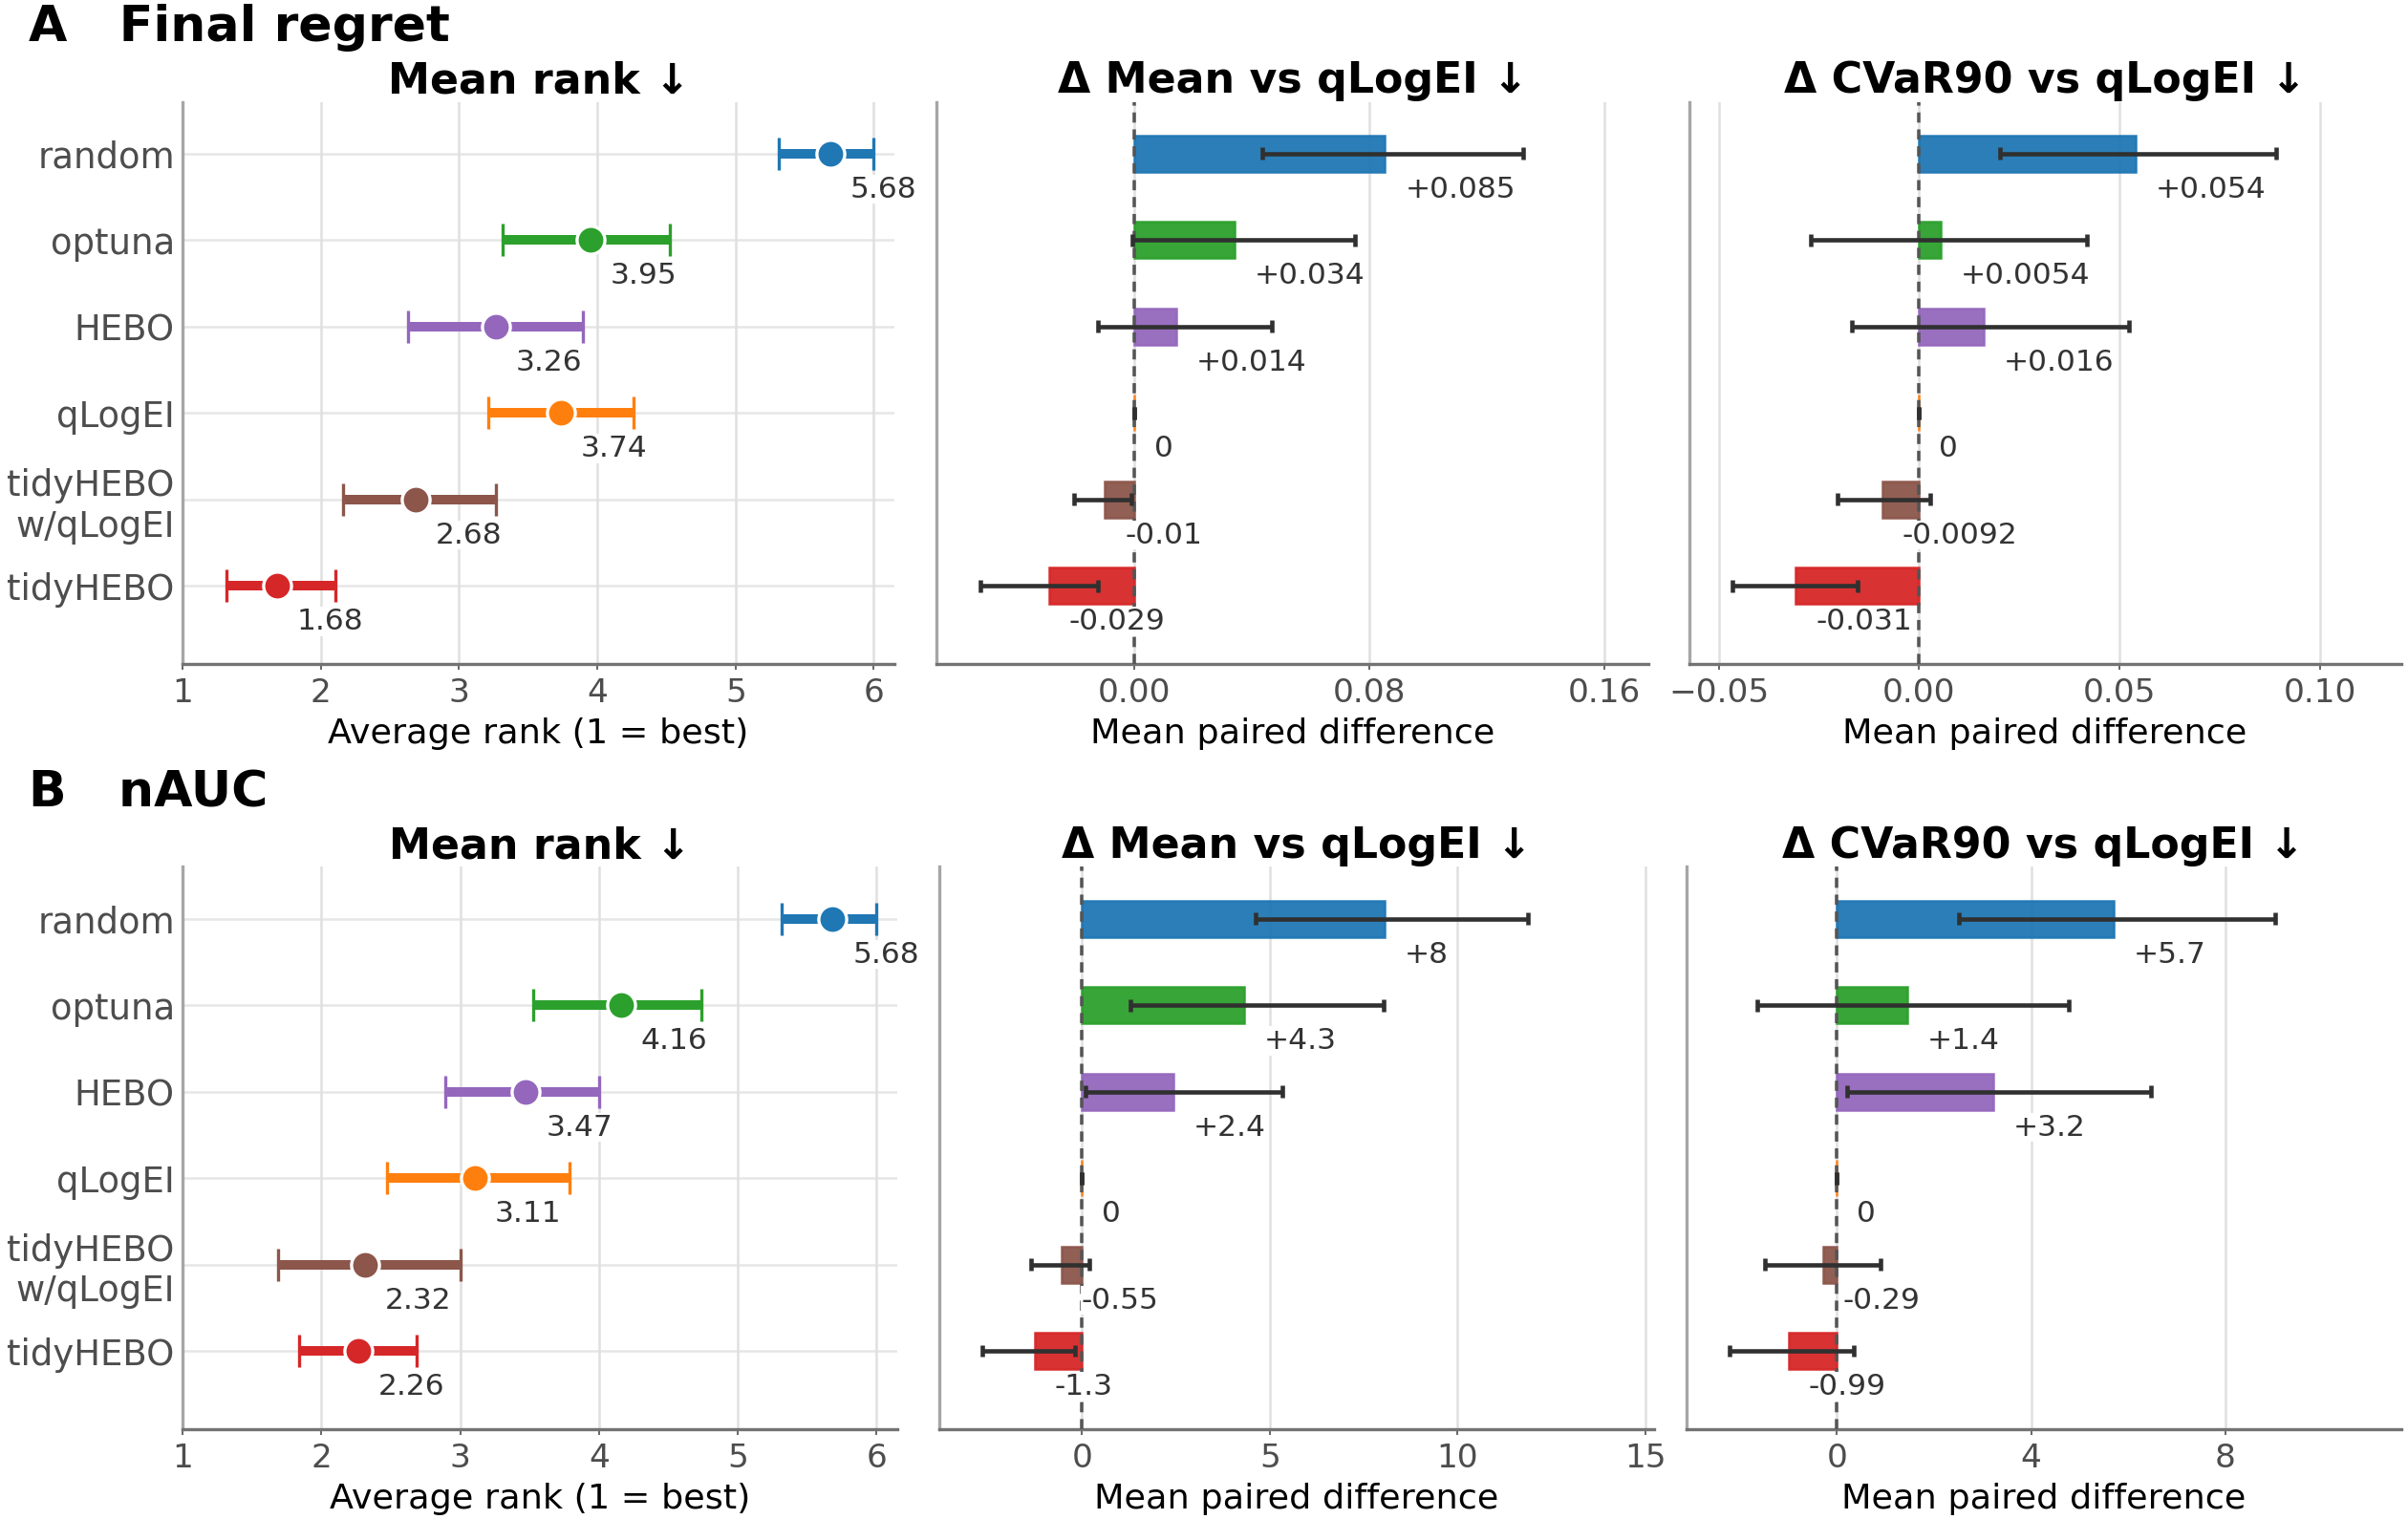

In [7]:
OUT = ROOT / "figures" / "olympus"
if SAVE_FIGURES:
    OUT.mkdir(parents=True, exist_ok=True)
    for suffix in ("pdf","svg","png"):
        fig.savefig(OUT / f"Figure_3_Olympus_sequential.{suffix}", dpi=300, facecolor="white")
    runs.to_csv(OUT / "sequential_paired_run_metrics.csv", index=False)
    task_metrics.to_csv(OUT / "task_metrics.csv", index=False)
    summary.to_csv(OUT / "sequential_figure_values.csv")
    coverage.to_csv(OUT / "sequential_coverage.csv", index=False)
    manifest = dict(baseline=BASELINE, difference="method minus same-task baseline; CVaR difference is difference of CVaRs", q=Q, metrics=METRICS, models=MODELS, labels=LABELS, colors=COLORS,
        bootstrap_samples=N_BOOT, bootstrap_seed=BOOT_SEED,
        interval="pointwise 95% paired task bootstrap, conditional on observed repeats",
        cvar_alpha=CVAR_ALPHA, cvar_definition="repository mean(values >= quantile(alpha))",
        aggregation="mean/CVaR over paired seeds per task, then equal mean across tasks",
        rank="rank of task mean; average across tasks; whiskers pointwise 95% task-bootstrap intervals",
        nAUC="repository regret_auc: un-averaged normalized-regret trapezoidal area",
        snapshot=snapshot.relative_to(ROOT).as_posix() if (SAVE_HISTORY or INPUT_SNAPSHOT) else None,
        source_fingerprint=snapshot_id, tasks=used_tasks, excluded_tasks=excluded,
        metric_hashes=metric_hashes, versions={m:importlib.metadata.version(m)
            for m in ("numpy","pandas","matplotlib")})
    (OUT / "sequential_analysis_manifest.json").write_bytes(json_bytes(manifest))
    print("Figure and analysis:",OUT)

# Display the generated figure when running in Jupyter.
from IPython import get_ipython
if get_ipython() is not None:
    from IPython.display import Image, display
    display(Image(filename=str(ROOT / 'figures/olympus/Figure_3_Olympus_sequential.png')))
